# CodeNova AI/ML Internship — Task 1: Exploratory Data Analysis

## Project Overview

This project performs Exploratory Data Analysis (EDA) on the Breast Cancer Wisconsin (Diagnostic) dataset.

### Objectives
- Load and understand the dataset.
- Examine data types and statistical summaries.
- Check missing values and duplicate records.
- Detect potential outliers using the IQR method.
- Visualize feature distributions and relationships.
- Identify meaningful observations from the analysis.

### Tools and Libraries
Python, Pandas, NumPy, Matplotlib, Seaborn, and Jupyter Notebook.

### Dataset
Breast Cancer Wisconsin (Diagnostic) dataset from the UCI Machine Learning Repository.

**Target variable:** `diagnosis` (`B` = Benign, `M` = Malignant).

### Step 1: Importing Libraries

- **Pandas:** Used to load, organize, and analyze tabular data.
- **NumPy:** Provides numerical computing operations.
- **Matplotlib:** Used to create plots and charts.
- **Seaborn:** Helps create statistical visualizations.

These libraries support the data analysis and visualization steps in this project.

In [187]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("CodeNova Task 1 - EDA")
print("Libraries imported successfully!")

CodeNova Task 1 - EDA
Libraries imported successfully!


In [189]:
import sklearn

print("Scikit-learn is installed!")
print("Version:", sklearn.__version__)

Scikit-learn is installed!
Version: 1.9.0


### Step 2: Dataset Loading

The Breast Cancer Wisconsin (Diagnostic) dataset was loaded into a Pandas DataFrame using `pd.read_csv()`.

- **Dataset file:** `wdbc.data`
- **Column names:** Assigned using the dataset documentation.
- **`header=None`:** Specifies that the file does not contain a header row.
- **`names=columns`:** Assigns descriptive names to the columns.
- **DataFrame (`df`):** Stores the dataset for further analysis.

The dataset contains an ID column, a diagnosis column, and 30 numerical features.

In [190]:
import pandas as pd

# Dataset folder path
folder_path = r"C:\Users\lakes\OneDrive\Desktop\CodeNova\Task-1\breast+cancer+wisconsin+diagnostic"

# Column names from the UCI dataset documentation
columns = [
    "ID", "diagnosis",
    "radius_mean", "texture_mean", "perimeter_mean",
    "area_mean", "smoothness_mean", "compactness_mean",
    "concavity_mean", "concave_points_mean", "symmetry_mean",
    "fractal_dimension_mean",
    "radius_se", "texture_se", "perimeter_se", "area_se",
    "smoothness_se", "compactness_se", "concavity_se",
    "concave_points_se", "symmetry_se", "fractal_dimension_se",
    "radius_worst", "texture_worst", "perimeter_worst",
    "area_worst", "smoothness_worst", "compactness_worst",
    "concavity_worst", "concave_points_worst", "symmetry_worst",
    "fractal_dimension_worst"
]

# Read the data file
df = pd.read_csv(
    folder_path + r"\wdbc.data",
    header=None,
    names=columns
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (569, 32)


,ID,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### Step 3: Dataset Profiling

This step examines the dataset's dimensions, column information, missing values, and statistical characteristics.

- **Dataset dimensions (`df.shape`):** The dataset contains 569 rows and 32 columns.
- **Column information (`df.info()`):** Displays column names, data types, and non-null counts.
- **Missing-value check (`df.isnull().sum()`):** Checks the number of missing values in each column.
- **Statistical summary (`df.describe()`):** Provides count, mean, standard deviation, minimum, maximum, and quartile values for numerical columns.

**Observation:** The dataset contains 569 records and 32 columns. The missing-value check found no missing values, so imputation was not required.

In [191]:
# 1. Dataset dimensions
print("Dataset shape:", df.shape)

# 2. Column names and data types
print("\nDataset information:")
df.info()

# 3. Check missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# 4. Statistical summary
print("\nStatistical summary:")
df.describe()

Dataset shape: (569, 32)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-

,ID,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [192]:
# Check duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


### Step 4: Missing Values and Duplicate Checks

This step checks the dataset for missing entries and duplicate records.

- **Missing values (`df.isnull().sum()`):** Counts missing values in each column.
- **Duplicate rows (`df.duplicated().sum()`):** Counts repeated rows in the dataset.

**Observation:**
- Total missing values: 0.
- Total duplicate rows: 0.
- No missing-value imputation or duplicate-row removal was required.

In [193]:
# Count missing values in the dataset
missing_values = df.isnull().sum()

print("Total missing values:", missing_values.sum())
print("\nColumns with missing values:")
print(missing_values[missing_values > 0])

Total missing values: 0

Columns with missing values:
Series([], dtype: int64)


### Step 5: Outlier Detection Using the IQR Method

The Interquartile Range (IQR) method was used to identify potential outliers in the numerical features.

- **Q1:** First quartile (25th percentile).
- **Q3:** Third quartile (75th percentile).
- **IQR:** Difference between Q3 and Q1.
- **Lower bound:** Q1 − 1.5 × IQR.
- **Upper bound:** Q3 + 1.5 × IQR.

Values below the lower bound or above the upper bound were identified as potential outliers.

**Observation:** The analysis identified 608 potential outlier values across the numerical features. These values were retained because potential outliers are not necessarily errors and may represent genuine measurements.



In [194]:
# Outlier detection using the IQR method

numerical_df = df.drop(columns=["ID", "diagnosis"])

Q1 = numerical_df.quantile(0.25)
Q3 = numerical_df.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_count = (
    (numerical_df < lower_bound) |
    (numerical_df > upper_bound)
).sum()

print("Outlier count for each numerical feature:")
print(outlier_count.sort_values(ascending=False))

print("\nTotal potential outlier values:", outlier_count.sum())

Outlier count for each numerical feature:
area_se                    65
radius_se                  38
perimeter_se               38
area_worst                 35
smoothness_se              30
fractal_dimension_se       28
compactness_se             28
symmetry_se                27
area_mean                  25
fractal_dimension_worst    24
symmetry_worst             23
concavity_se               22
texture_se                 20
concave_points_se          19
concavity_mean             18
radius_worst               17
compactness_worst          16
compactness_mean           16
symmetry_mean              15
fractal_dimension_mean     15
perimeter_worst            15
radius_mean                14
perimeter_mean             13
concavity_worst            12
concave_points_mean        10
texture_mean                7
smoothness_worst            7
smoothness_mean             6
texture_worst               5
concave_points_worst        0
dtype: int64

Total potential outlier values: 608


### Step 6: Diagnosis Distribution

A count plot was created to visualize the distribution of the two diagnosis categories in the dataset.

- **B:** Benign cases.
- **M:** Malignant cases.
- `value_counts()` was used to count the records in each category.
- The count plot helps compare the number of cases in both categories.

**Observation:** The plot shows the distribution of benign and malignant cases. Comparing the category counts helps determine whether the target variable is balanced or imbalanced.

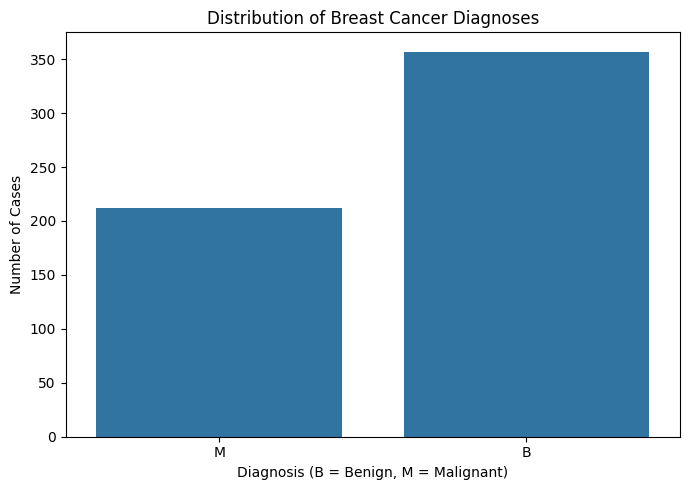

Diagnosis counts:
diagnosis
B    357
M    212
Name: count, dtype: int64


In [195]:
import matplotlib.pyplot as plt
import seaborn as sns

diagnosis_counts = df["diagnosis"].value_counts()

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="diagnosis")

plt.title("Distribution of Breast Cancer Diagnoses")
plt.xlabel("Diagnosis (B = Benign, M = Malignant)")
plt.ylabel("Number of Cases")
plt.tight_layout()
plt.savefig("diagnosis_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

print("Diagnosis counts:")
print(diagnosis_counts)

### Step 7: Feature Distribution Analysis

Histograms were created for the first six numerical features to examine the distribution of their values.

- **X-axis:** Feature values.
- **Y-axis:** Frequency of observations.
- **Bins:** Group feature values into intervals.
- The histograms help identify the spread, concentration, and shape of each feature's distribution.

**Observation:** The histograms provide an overview of how values are distributed across the selected numerical features. The shape of each distribution can help identify skewness and areas where observations are concentrated.

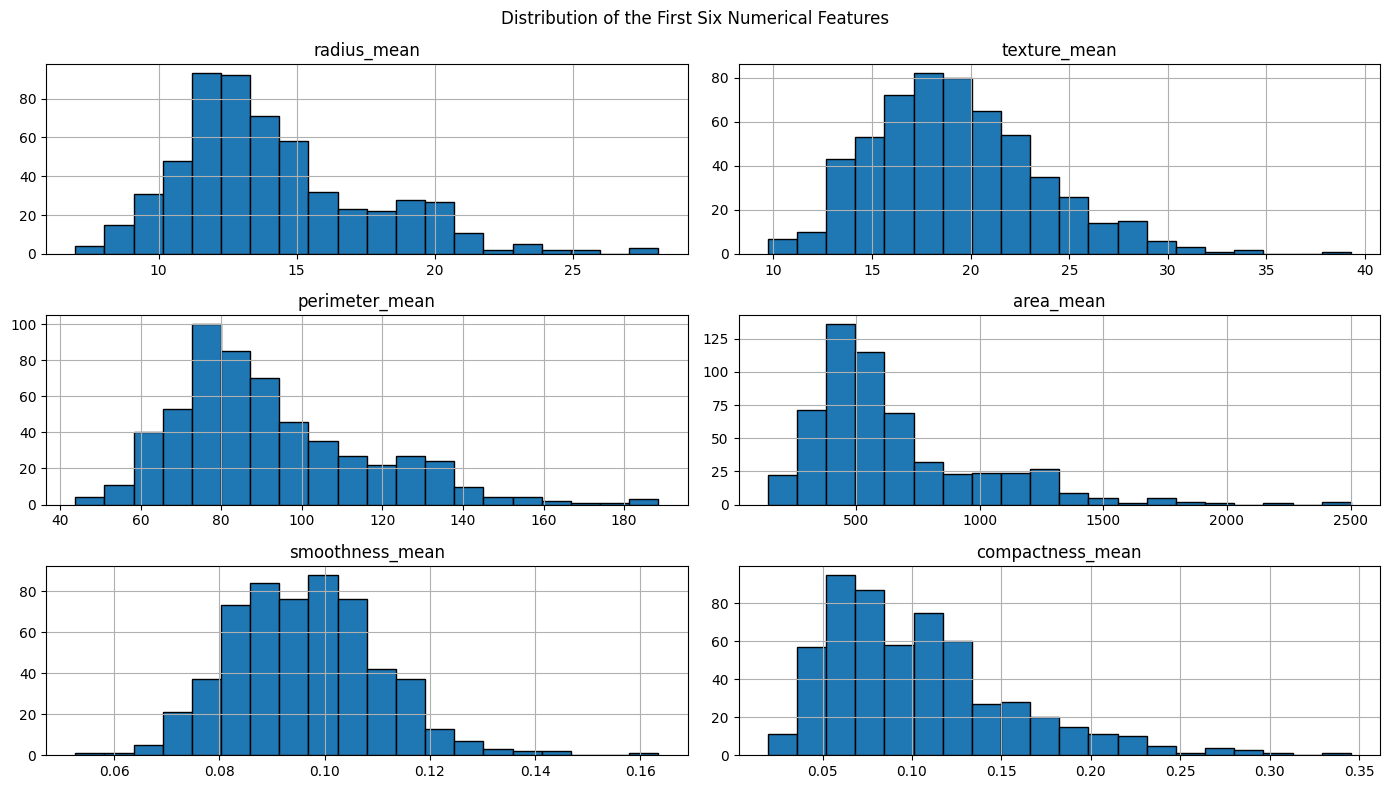

In [196]:
# Select numerical features, excluding ID
numerical_df = df.drop(columns=["ID", "diagnosis"])

# Plot distributions of the first 6 features
numerical_df.iloc[:, :6].hist(
    figsize=(14, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of the First Six Numerical Features")
plt.tight_layout()
plt.savefig("feature_histograms.png", dpi=300, bbox_inches="tight")
plt.show()

### Step 8: Boxplot Analysis

Boxplots were created for the first six numerical features to examine their distribution, spread, and potential outliers.

- **Median:** The central line inside the box.
- **Interquartile Range (IQR):** The box represents the middle 50% of the observations.
- **Whiskers:** Show the range of values within the plotting rule.
- **Individual points:** Values beyond the whiskers may indicate potential outliers.

**Observation:** The boxplots help compare the spread and variability of the selected features and visually identify values that may require further investigation. Potential outliers are not automatically considered errors.

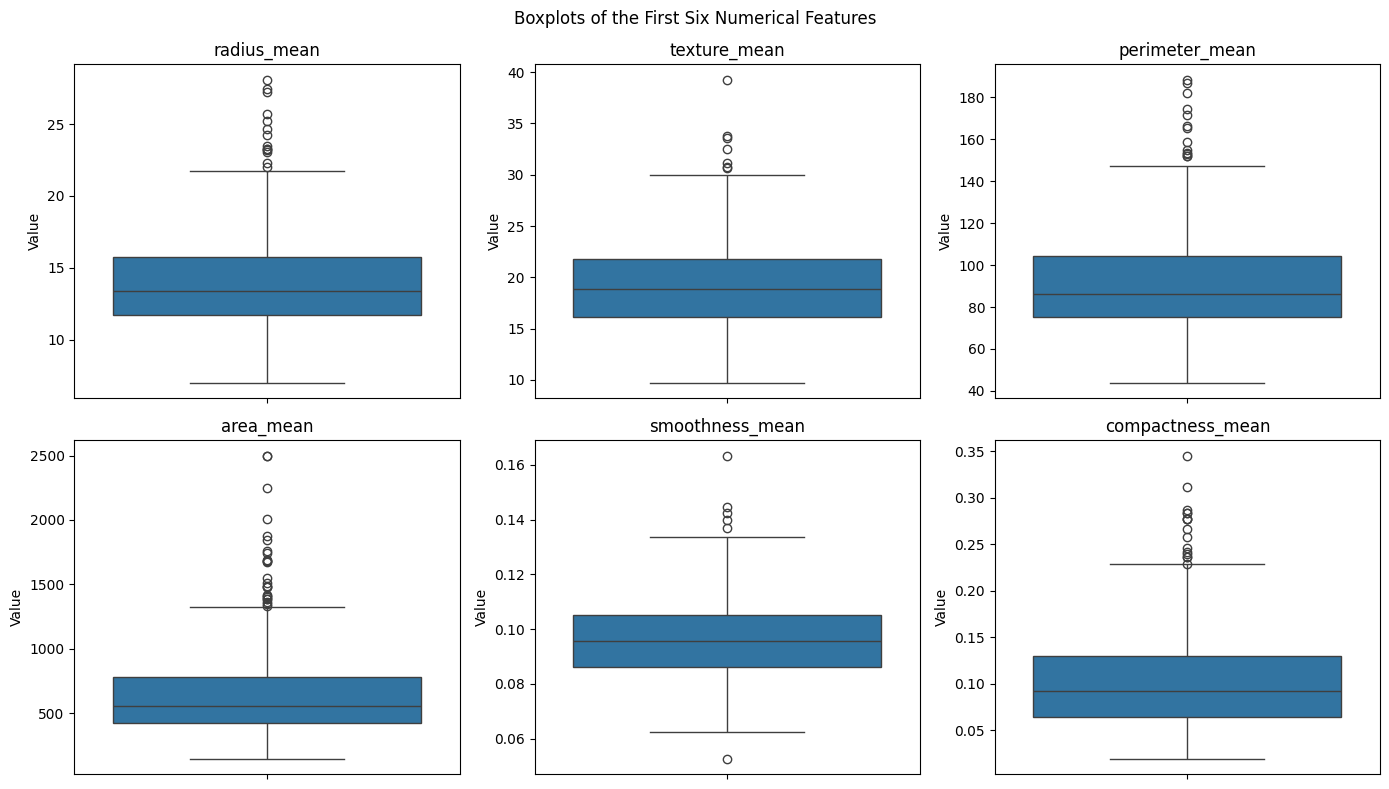

In [197]:
# Boxplots for the first 6 numerical features

plt.figure(figsize=(14, 8))

for i, column in enumerate(numerical_df.columns[:6], 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=numerical_df[column])
    plt.title(column)
    plt.ylabel("Value")

plt.suptitle("Boxplots of the First Six Numerical Features")
plt.tight_layout()
plt.savefig("feature_boxplots.png", dpi=300, bbox_inches="tight")
plt.show()

### Step 9: Correlation Analysis

A correlation heatmap was created to examine the relationships between the 30 numerical features.

- **Correlation coefficient:** Measures the strength and direction of a linear relationship between two features.
- **Positive correlation:** Values closer to +1 indicate a strong positive relationship.
- **Negative correlation:** Values closer to −1 indicate a strong negative relationship.
- **Weak correlation:** Values closer to 0 indicate a weak linear relationship.

**Observation:** The heatmap helps identify strongly related numerical features and provides insight into potential relationships among the measurements. Correlation does not necessarily imply causation.

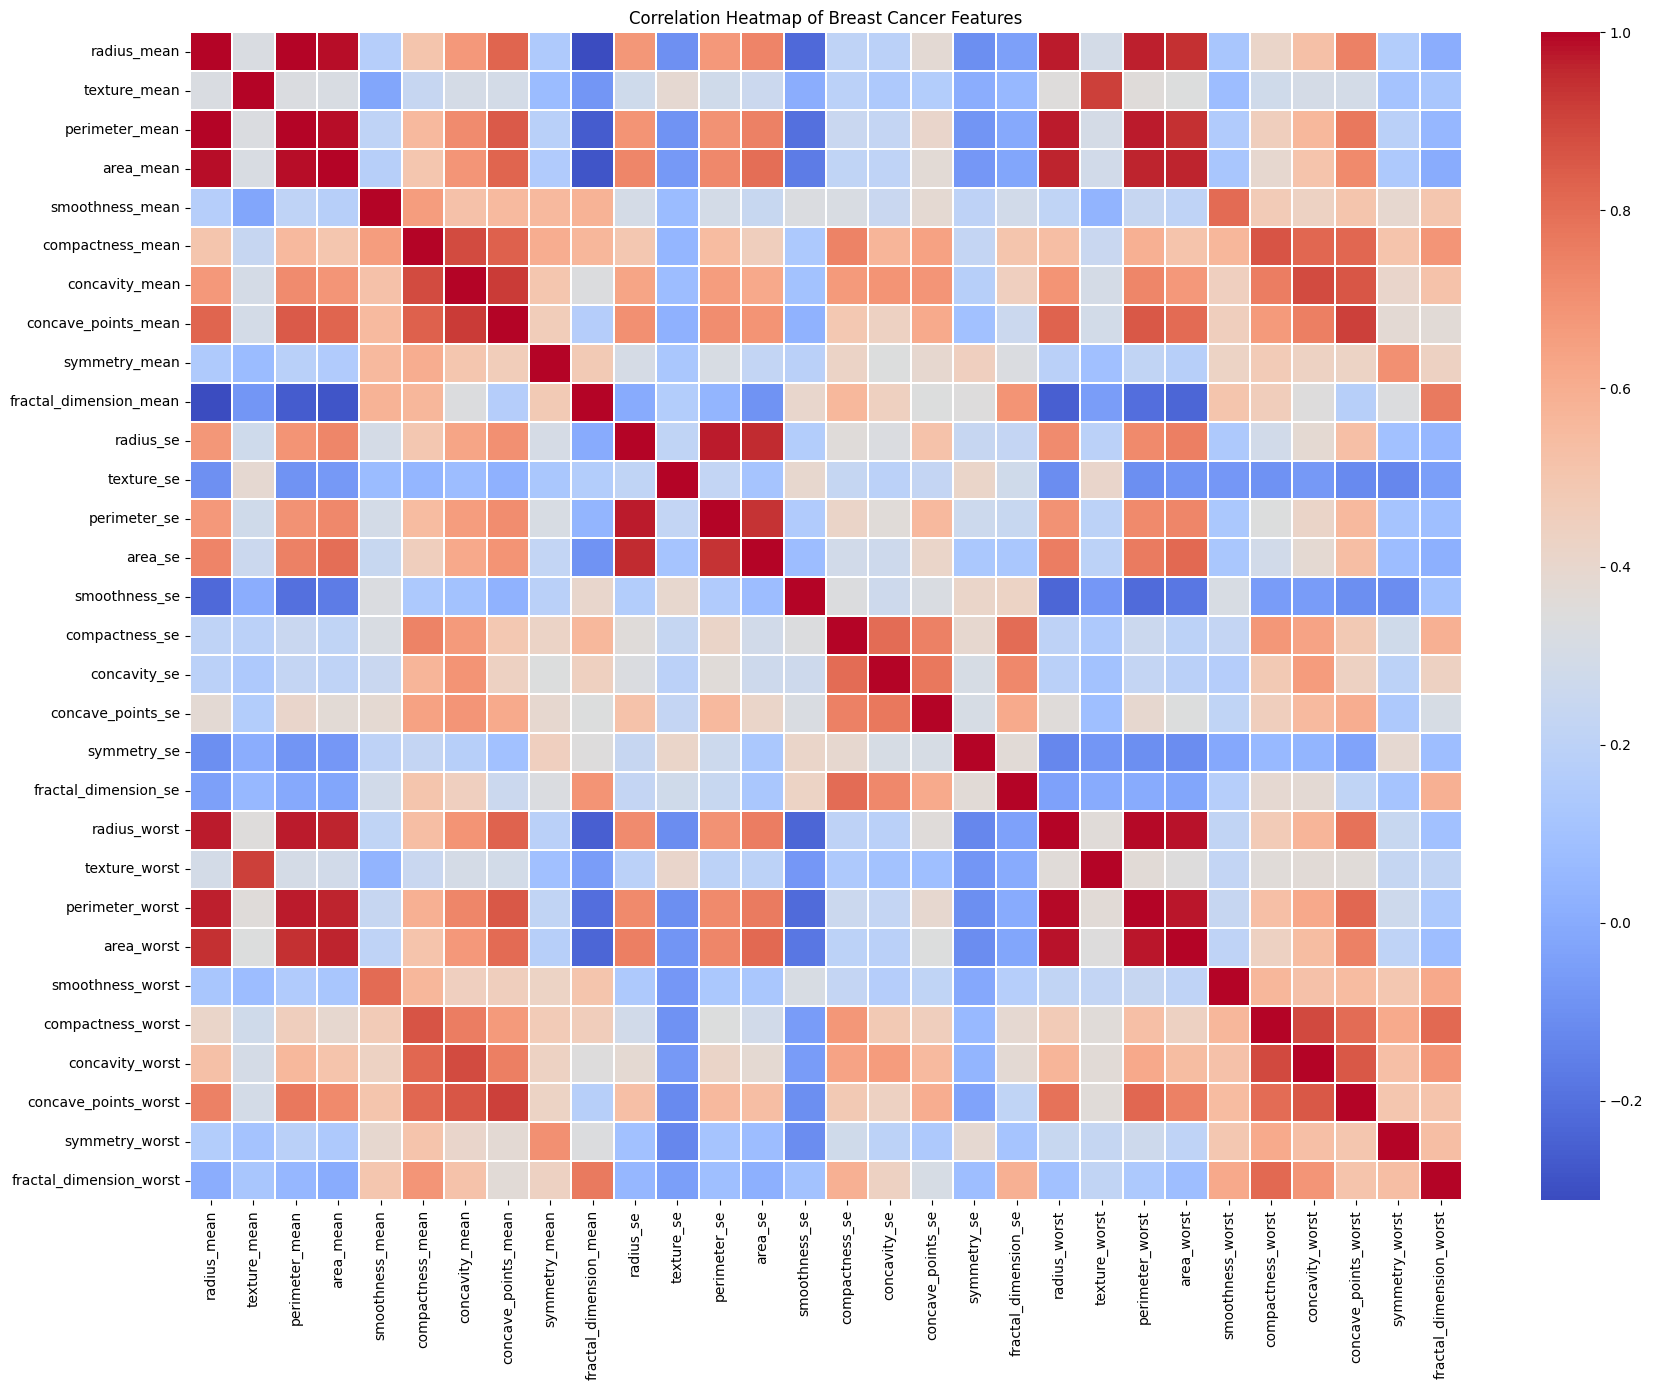

In [198]:
# Correlation heatmap

correlation_matrix = numerical_df.corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    annot=False,
    linewidths=0.3
)

plt.title("Correlation Heatmap of Breast Cancer Features")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

### Step 10: Pairwise Scatter Plot Analysis

Pairwise scatter plots were created to examine relationships between selected numerical features. The points are colored according to the diagnosis category.

- **X-axis and Y-axis:** Represent two numerical features being compared.
- **Each point:** Represents one observation from the dataset.
- **Colors:** Distinguish between the diagnosis categories, malignant (M) and benign (B).
- **Clusters and separation:** Help identify patterns and differences between the two categories.

**Observation:** The scatter plots help visualize relationships between features and assess whether the diagnosis categories show distinguishable patterns. The degree of separation varies depending on the features being compared.

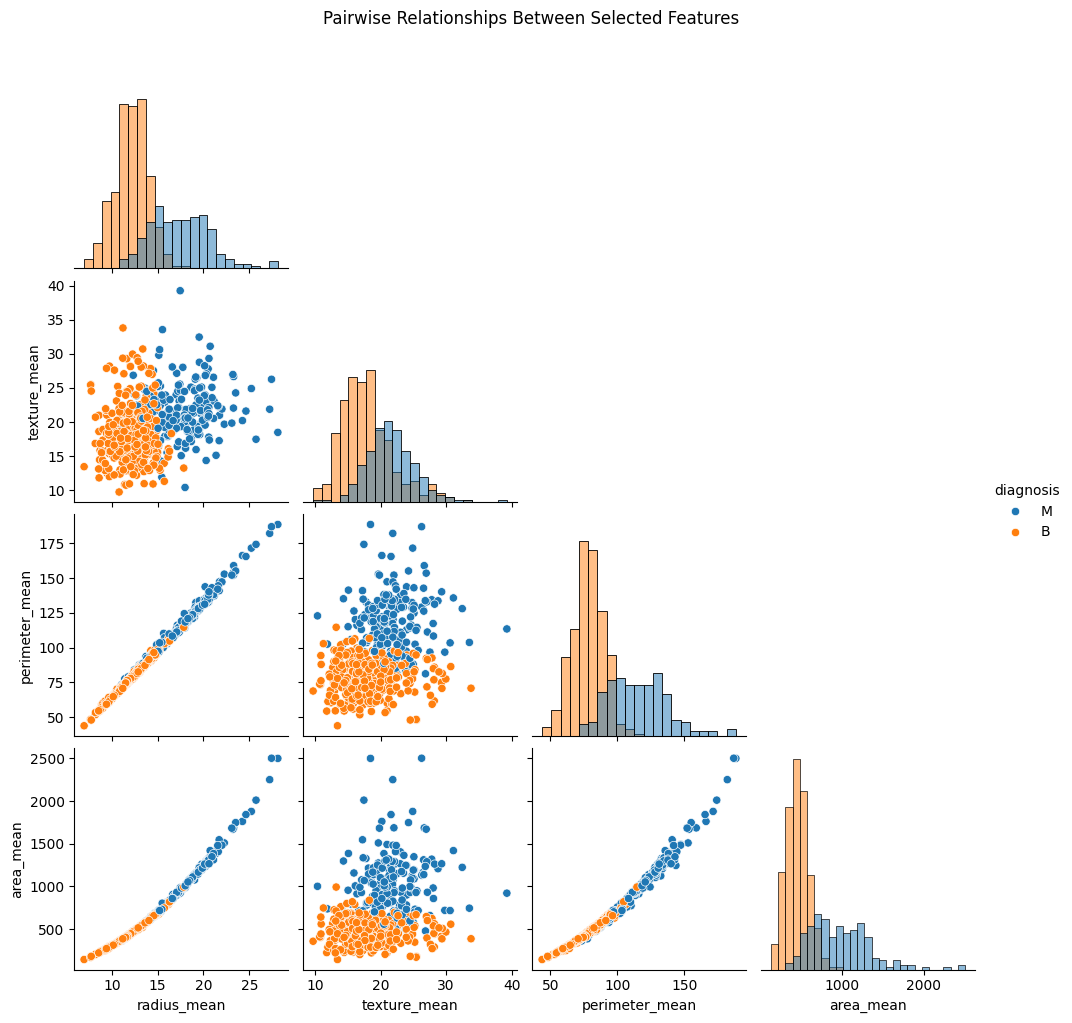

In [199]:
# Pairwise scatter plots for selected features

selected_features = [
    "radius_mean",
    "texture_mean",
    "perimeter_mean",
    "area_mean"
]

pair_plot=sns.pairplot(
    df,
    vars=selected_features,
    hue="diagnosis",
    diag_kind="hist",
    corner=True
)

plt.suptitle(
    "Pairwise Relationships Between Selected Features",
    y=1.02
)

pair_plot.savefig(
    "pairwise_scatterplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Step 11: Comparison of Average Feature Values by Diagnosis

The dataset was grouped by diagnosis, and the average values of four numerical features were calculated for each category: malignant (M) and benign (B).

- **radius_mean:** Average radius of the cell nuclei.
- **texture_mean:** Average variation in grayscale intensity.
- **perimeter_mean:** Average perimeter of the cell nuclei.
- **area_mean:** Average area of the cell nuclei.

**Observation:** Comparing these averages helps identify differences in the measured features between malignant and benign cases. The numerical summary can help reveal which features may be useful for distinguishing the two diagnosis categories.

In [200]:
# Compare numerical measurements by diagnosis

diagnosis_summary = df.groupby("diagnosis")[
    ["radius_mean", "texture_mean", "perimeter_mean", "area_mean"]
].mean().round(2)

print("Average feature values by diagnosis:")
print(diagnosis_summary)

print("\nDataset shape:", df.shape)
print("Number of numerical features:", numerical_df.shape[1])
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Average feature values by diagnosis:
           radius_mean  texture_mean  perimeter_mean  area_mean
diagnosis                                                      
B                12.15         17.91           78.08     462.79
M                17.46         21.60          115.37     978.38

Dataset shape: (569, 32)
Number of numerical features: 30
Missing values: 0
Duplicate rows: 0


In [201]:
import os
import shutil

source = r"C:\Users\lakes"
destination = r"C:\Users\lakes\OneDrive\Desktop\CodeNova\Task-1\images"

os.makedirs(destination, exist_ok=True)

files = [
    "diagnosis_distribution.png",
    "feature_histograms.png",
    "feature_boxplots.png",
    "correlation_heatmap.png",
    "pairwise_scatterplot.png"
]

for file in files:
    src = os.path.join(source, file)
    if os.path.exists(src):
        shutil.copy2(src, os.path.join(destination, file))
        print("Copied:", file)
    else:
        print("Not found:", file)

print("\nImages folder:", destination)

Copied: diagnosis_distribution.png
Copied: feature_histograms.png
Copied: feature_boxplots.png
Copied: correlation_heatmap.png
Copied: pairwise_scatterplot.png

Images folder: C:\Users\lakes\OneDrive\Desktop\CodeNova\Task-1\images


In [202]:
import os
print(os.getcwd())
print([f for f in os.listdir() if f.endswith(".png")])

C:\Users\lakes
['correlation_heatmap.png', 'diagnosis_distribution.png', 'feature_boxplots.png', 'feature_histograms.png', 'pairwise_scatterplot.png']


## Final Conclusion

The Exploratory Data Analysis (EDA) was performed on the Breast Cancer Wisconsin (Diagnostic) dataset containing 569 observations and 30 numerical features, along with an ID and diagnosis column.

### Key Findings

- **Dataset structure:** The dataset contains numerical measurements of cell nuclei and a diagnosis label.
- **Data quality:** No missing values or duplicate rows were identified.
- **Outlier analysis:** The IQR method identified potential outlier values. They were retained because they may represent genuine observations and require further investigation before removal.
- **Feature distributions:** Histograms and boxplots were used to understand the distributions, spread, and potential outliers of selected features.
- **Correlation analysis:** The heatmap helped examine relationships between numerical features.
- **Pairwise analysis:** Scatter plots helped visualize relationships between selected features and compare diagnosis categories.
- **Diagnosis comparison:** Group averages were calculated to explore differences between malignant and benign cases.

### Overall Conclusion

The analysis provided an initial understanding of the dataset's structure, quality, feature relationships, and diagnosis categories. These findings can support further statistical analysis and machine learning model development. Any decisions about removing outliers or selecting features should be supported